# 02 — Waveform Analysis: justifying the Phase 2 preprocessing

Every preprocessing parameter in `configs/data.yaml` (`preprocessing`) is chosen from measurements
in this notebook (summary: `PROJECT_CONTEXT.md` §11H, Decisions 018–022). Data: the Phase 1
exploration subsets (seeded, event-complete; ComCat 4,019 traces, Exotic 1,133 traces) — **not**
a training set, and nothing here is a model result.

Tags: **Observed** (measured here) · **Inferred** · **Documented** (dataset authors) · **Decision**.

## 0. Setup

In [1]:
import os
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.signal import welch

# Optional — Colab + Drive: from google.colab import drive; drive.mount("/content/drive")
# os.environ["SEISMIC_DATA_ROOT"] = "/content/drive/MyDrive/seismic-data"

def find_project_root(start: Path = Path.cwd()) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "configs" / "config.yaml").is_file():
            return candidate
    raise FileNotFoundError("configs/config.yaml not found above the working directory")

PROJECT_ROOT = find_project_root()
from seismic_ml.config import load_config
from seismic_ml.paths import resolve_paths
from seismic_ml.data import pnw
from seismic_ml.data.loader import load_collection_metadata, waveform_path
from seismic_ml.data.seisbench_format import SeisBenchWaveformStore
from seismic_ml.data.splits import load_split_table
from seismic_ml.data.processed import ProcessedEventDataset
from seismic_ml.preprocessing import preprocess_waveform, preprocess_observation

CONFIG = load_config(PROJECT_ROOT / "configs" / "config.yaml")
DATA_CFG, PRE = CONFIG["data"], CONFIG["data"]["preprocessing"]
PATHS = resolve_paths(CONFIG, project_root=PROJECT_ROOT)
RAW = PATHS.dataset_raw_dir(DATA_CFG)
FS = float(DATA_CFG["waveform"]["sample_rate"])
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
cc = load_collection_metadata(RAW, DATA_CFG, "comcat"); ex = load_collection_metadata(RAW, DATA_CFG, "exotic")
cc_store = SeisBenchWaveformStore(waveform_path(RAW, DATA_CFG, "comcat"))
ex_store = SeisBenchWaveformStore(waveform_path(RAW, DATA_CFG, "exotic"))
print("preprocessing config:", PRE)

preprocessing config: {'detrend': 'linear', 'taper_s': 2.0, 'bandpass': {'freqmin': 1.0, 'freqmax': 16.0, 'corners': 4, 'zerophase': True}, 'window': {'pre_p_s': 10.0, 'post_p_s': 50.0, 'edge_margin_s': 5.0, 'resample_margin_s': 1.0}, 'target_sample_rate': 50, 'normalization': {'method': 'std', 'scope': 'station'}, 'p_wave_alignment': True, 'quality_checks': {'require_p_pick': True, 'clip_min_samples': 10}}


In [2]:
# One record per subset trace with a live vertical component and >= 35 s before P:
# Welch PSD of a 20.5 s signal window (P-0.5 s ... P+20 s) and of a 20.5 s pre-P noise window.
records = []
for coll, meta, store, lab_col in [("comcat", cc, cc_store, "source_type_pnsn_label"), ("exotic", ex, ex_store, "source_type")]:
    m = meta[meta.trace_name.isin(store.available_trace_names())].dropna(subset=["trace_P_arrival_sample"])
    for r in m.itertuples():
        x = store.get(r.trace_name); p = int(r.trace_P_arrival_sample)
        if not np.any(x[2]) or p < 3500:
            continue
        sig, noi = x[2, p - 50: p + 2000], x[2, p - 3200: p - 1150]
        f, ps = welch(sig - sig.mean(), fs=FS, nperseg=512)
        _, pn = welch(noi - noi.mean(), fs=FS, nperseg=512)
        records.append({"coll": coll, "label": getattr(r, lab_col), "band": r.station_channel_code, "ps": ps, "pn": pn})
freqs = f
print("traces analysed:", len(records), pd.Series([r["band"] for r in records]).value_counts().to_dict())

traces analysed: 5063 {'EH': 2744, 'BH': 1680, 'HH': 639}


## 1. Upper corner: what do BH channels contain above 20 Hz?

EH: median PSD ratio (18–19.5 Hz)/(21–23 Hz) = 2.7
BH: median PSD ratio (18–19.5 Hz)/(21–23 Hz) = 198.3
HH: median PSD ratio (18–19.5 Hz)/(21–23 Hz) = 2.1


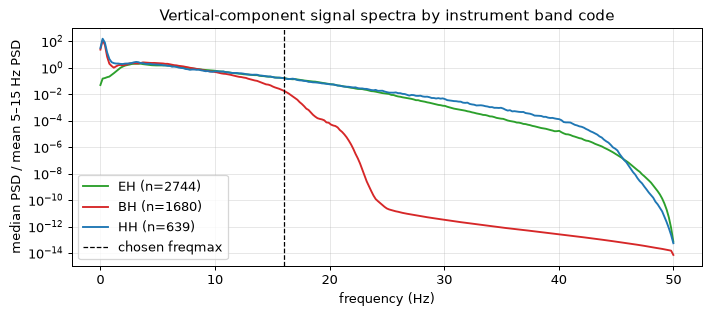

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for band, color in [("EH", "tab:green"), ("BH", "tab:red"), ("HH", "tab:blue")]:
    sel = np.array([r["ps"] for r in records if r["band"] == band])
    norm = sel / sel[:, (freqs > 5) & (freqs < 15)].mean(axis=1, keepdims=True)
    ax.semilogy(freqs, np.median(norm, axis=0), color=color, label=f"{band} (n={len(sel)})")
ax.axvline(PRE["bandpass"]["freqmax"], color="k", ls="--", lw=1, label="chosen freqmax")
ax.set(xlabel="frequency (Hz)", ylabel="median PSD / mean 5–15 Hz PSD", title="Vertical-component signal spectra by instrument band code")
ax.legend(); fig.tight_layout()
for band in ["EH", "BH", "HH"]:
    sel = [r for r in records if r["band"] == band]
    ratio = np.median([r["ps"][(freqs > 18) & (freqs < 19.5)].mean() / r["ps"][(freqs > 21) & (freqs < 23)].mean() for r in sel])
    print(f"{band}: median PSD ratio (18–19.5 Hz)/(21–23 Hz) = {ratio:.1f}")

**Observed:** BH spectra collapse above ~20 Hz (PSD drops by ~2 orders of magnitude between 19 and
22 Hz), EH/HH do not. **Documented:** the curators upsampled BH channels to 100 Hz. **Inferred:** BH
was recorded at 40 samples/s; everything above ~18 Hz is an instrument fingerprint (and instrument
mix differs slightly by class, §11C.8). **Decision 018:** upper corner 16 Hz (BH anti-alias roll-off
starts below 20 Hz).

## 2. Lower corner: spectral SNR by frequency

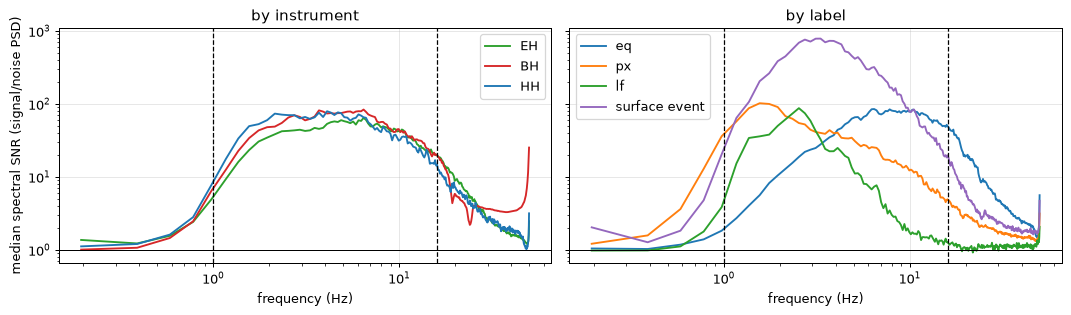

In [4]:
def snr_curve(sel):
    return np.median(np.array([r["ps"] / r["pn"] for r in sel]), axis=0)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for band, color in [("EH", "tab:green"), ("BH", "tab:red"), ("HH", "tab:blue")]:
    axes[0].loglog(freqs[1:], snr_curve([r for r in records if r["band"] == band])[1:], color=color, label=band)
for lab, color in [("eq", "tab:blue"), ("px", "tab:orange"), ("lf", "tab:green"), ("surface event", "tab:purple")]:
    axes[1].loglog(freqs[1:], snr_curve([r for r in records if r["label"] == lab])[1:], color=color, label=lab)
for ax in axes:
    ax.axhline(1, color="k", lw=0.8)
    for v in (PRE["bandpass"]["freqmin"], PRE["bandpass"]["freqmax"]):
        ax.axvline(v, color="k", ls="--", lw=1)
    ax.set(xlabel="frequency (Hz)"); ax.legend()
axes[0].set(ylabel="median spectral SNR (signal/noise PSD)", title="by instrument"); axes[1].set(title="by label")
fig.tight_layout()

**Observed:** below ~0.5 Hz the median SNR is ≈ 1 for every instrument (microseism band); EH
(1 Hz geophones) roll off below 1 Hz. Explosions (`px`) and `lf` events carry relatively more
0.5–2 Hz energy than earthquakes. **Inferred:** part of that difference may be magnitude/distance
(explosions are recorded farther away and are slightly larger, §11C.8), not source type.
**Decision 018:** lower corner 1 Hz — removes the microseism and the band where EH vs BH/HH
responses differ most (amplitudes are raw counts). **Trade-off recorded:** some low-frequency
explosion energy is attenuated; a 0.5 Hz lower corner is a planned ablation (Phase 4/10).

## 3. Window length: how long is the signal after P?

In [5]:
from scipy.signal import butter, sosfiltfilt
sos = butter(PRE["bandpass"]["corners"], [PRE["bandpass"]["freqmin"], PRE["bandpass"]["freqmax"]], btype="bandpass", fs=FS, output="sos")
dur = []
for coll, meta, store, lab_col in [("comcat", cc, cc_store, "source_type_pnsn_label"), ("exotic", ex, ex_store, "source_type")]:
    m = meta[meta.trace_name.isin(store.available_trace_names())].dropna(subset=["trace_P_arrival_sample"])
    for r in m.itertuples():
        x = store.get(r.trace_name); p = int(r.trace_P_arrival_sample)
        live = [c for c in range(3) if np.any(x[c])]
        if not live or p < 3100:
            continue
        y = sosfiltfilt(sos, x[live] - x[live].mean(axis=1, keepdims=True), axis=1)
        env = np.sqrt(np.convolve(np.sum(y ** 2, axis=0), np.ones(100) / 100, mode="same"))
        above = np.flatnonzero(env[p:] > 3 * np.median(env[p - 3000: p - 200]))
        dur.append({"label": getattr(r, lab_col), "dur": above[-1] / FS if above.size else 0.0,
                    "mag": getattr(r, "preferred_source_magnitude", np.nan)})
dur = pd.DataFrame(dur)
post = PRE["window"]["post_p_s"]
display(dur.groupby("label").dur.describe(percentiles=[.5, .8, .9]).round(1))
print(f"fraction of traces whose signal ends within the {post:.0f} s post-P window:",
      dur.groupby("label").dur.apply(lambda s: round(float((s <= post).mean()), 3)).to_dict())
sp = (cc.trace_S_arrival_sample - cc.trace_P_arrival_sample) / FS
print("S-P (s), full ComCat metadata, quantiles:", sp.quantile([.5, .9, .95, .99]).round(1).to_dict())
avail = (15001 - cc.trace_P_arrival_sample) / FS
print(f"ComCat traces with >= post_p + margins after P: {(avail >= post + PRE['window']['resample_margin_s'] + PRE['window']['edge_margin_s']).mean():.4%}")

,count,mean,std,min,50%,80%,90%,max
label,,,,,,,,
eq,2317.0,28.0,26.4,0.0,17.0,49.9,74.3,99.0
ex,63.0,33.1,20.9,0.0,26.9,44.6,65.7,92.2
lf,195.0,36.2,29.2,0.0,26.2,73.9,84.0,97.2
px,1344.0,35.9,21.7,0.0,30.6,52.8,68.8,99.5
qb,21.0,24.0,21.7,0.0,18.4,25.6,36.1,93.1
sn,4.0,64.4,41.4,11.5,73.2,96.8,98.3,99.8
sonic boom,198.0,42.9,33.8,0.0,33.8,72.6,103.6,110.0
su,72.0,32.7,26.8,0.0,21.9,56.3,80.9,100.2
surface event,769.0,63.4,34.4,0.0,65.8,101.4,109.8,110.0


fraction of traces whose signal ends within the 50 s post-P window: {'eq': 0.801, 'ex': 0.841, 'lf': 0.723, 'px': 0.773, 'qb': 0.905, 'sn': 0.25, 'sonic boom': 0.646, 'su': 0.764, 'surface event': 0.394, 'thunder': 0.414, 'uk': 1.0}
S-P (s), full ComCat metadata, quantiles: {0.5: 4.6, 0.9: 10.3, 0.95: 12.5, 0.99: 19.5}
ComCat traces with >= post_p + margins after P: 99.9570%


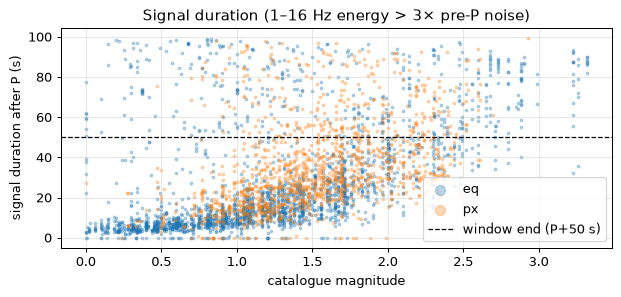

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.4))
sub = dur[dur.label.isin(["eq", "px"])].dropna(subset=["mag"])
for lab, color in [("eq", "tab:blue"), ("px", "tab:orange")]:
    s = sub[sub.label == lab]
    ax.scatter(s.mag, s.dur, s=4, alpha=0.3, color=color, label=lab)
ax.axhline(post, color="k", ls="--", lw=1, label=f"window end (P+{post:.0f} s)")
ax.set(xlabel="catalogue magnitude", ylabel="signal duration after P (s)", title="Signal duration (1–16 Hz energy > 3× pre-P noise)")
ax.legend(markerscale=4); fig.tight_layout()

**Observed:** duration grows with magnitude; 99 % of S–P times are ≤ 21 s; ~99.9 % of ComCat traces
have enough data after P for a 50 s post-P window plus margins. **Decision 020:** P-aligned window
[P − 10 s, P + 50 s] per station — contains P and S for ~all traces and the full signal for most;
the coda of the largest events is truncated (accepted; window length is a Phase 10 ablation).
Per-station P alignment also removes the Phase 1 collection artefact (origin- vs pick-aligned
windows); relative P times across stations are kept as metadata (`p_time_offset_s`), not as input.

## 4. Before / after preprocessing (seeded example)

channel mask: (True, True, True) | norm scale: (756.7164589069934, 756.7164589069934, 756.7164589069934)


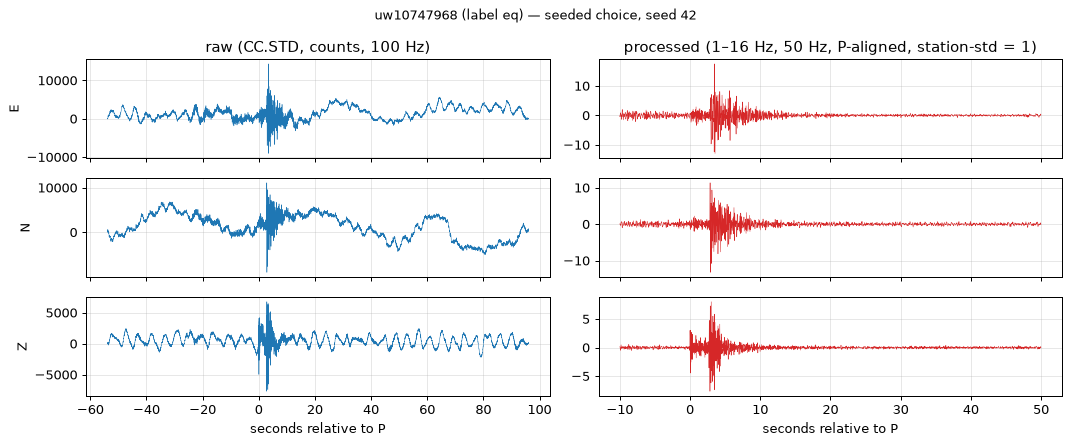

In [7]:
rng = np.random.default_rng(DATA_CFG["dataset"]["exploration_subset"]["seed"])
complete = pnw.complete_event_ids(cc, cc_store)
multi = cc[cc.event_id.isin(complete)].groupby("event_id").size()
event_id = rng.choice(sorted(multi.index[multi >= 3]))
event = pnw.rows_to_event(cc[cc.event_id == event_id], cc_store, label_column="source_type_pnsn_label")
obs = next(o for o in event.observations if o.waveform.data.any(axis=1).all())      # first 3-component station
out, info = preprocess_observation(obs, PRE)
fig, axes = plt.subplots(3, 2, figsize=(12, 5), sharex="col")
t_raw = np.arange(obs.waveform.num_samples) / FS
p_raw = (obs.p_arrival_time - obs.waveform.start_time).total_seconds()
t_out = np.arange(out.waveform.num_samples) / out.waveform.sampling_rate - PRE["window"]["pre_p_s"]
for c, comp in enumerate(obs.waveform.channels):
    axes[c, 0].plot(t_raw - p_raw, obs.waveform.data[c], lw=0.4); axes[c, 0].set_ylabel(comp)
    axes[c, 1].plot(t_out, out.waveform.data[c], lw=0.4, color="tab:red")
axes[0, 0].set_title(f"raw ({obs.station_id}, counts, 100 Hz)"); axes[0, 1].set_title("processed (1–16 Hz, 50 Hz, P-aligned, station-std = 1)")
for ax in axes[-1]: ax.set_xlabel("seconds relative to P")
fig.suptitle(f"{event.event_id} (label {event.label}) — seeded choice, seed {DATA_CFG['dataset']['exploration_subset']['seed']}", fontsize=10)
fig.tight_layout()
print("channel mask:", info["channel_mask"], "| norm scale:", info["norm_scale"])

## 5. Processed outputs: alignment, masks, normalisation, drops

In [8]:
split = load_split_table(PATHS.processed / "splits" / "s1_temporal" / "events.csv")
for coll in ("comcat", "exotic"):
    d = PATHS.processed / DATA_CFG["dataset"]["name"] / coll
    tr = pd.read_csv(d / "traces.csv")
    dp = (pd.to_datetime(tr.p_arrival_time, format="ISO8601") - pd.to_datetime(tr.window_start_time, format="ISO8601")).dt.total_seconds()
    drops = pd.read_csv(d / "dropped_traces.csv")
    print(f"{coll}: kept {len(tr)} traces / {tr.event_id.nunique()} events | P position in window: {dp.min():.3f}–{dp.max():.3f} s "
          f"| live-component patterns {tr.live_components.value_counts().to_dict()} | dropped {drops.reason.value_counts().to_dict()}")

comcat: kept 4018 traces / 1220 events | P position in window: 10.000–10.000 s | live-component patterns {'ENZ': 2896, 'Z': 1053, 'EN': 68, 'NZ': 1} | dropped {'window_out_of_range': 1}
exotic: kept 1112 traces / 728 events | P position in window: 10.000–10.000 s | live-component patterns {'ENZ': 581, 'Z': 511, 'EZ': 20} | dropped {'no_p_pick': 21}


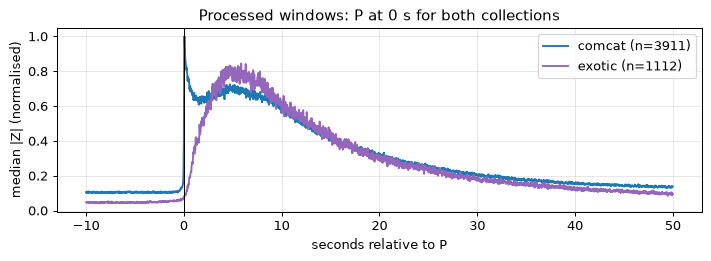

In [9]:
# Mean |amplitude| envelope of processed vertical components around P: ComCat vs exotic windows are now aligned identically.
fig, ax = plt.subplots(figsize=(8, 3))
for coll, color in [("comcat", "tab:blue"), ("exotic", "tab:purple")]:
    ds = ProcessedEventDataset(PATHS.processed / "pnw" / coll, split, ["train", "val", "test", "ood"])
    env = [np.abs(o.waveform.data[2]) for i in range(len(ds)) for o in ds[i].observations if o.metadata["channel_mask"][2]]
    ax.plot(np.arange(3000) / 50 - 10, np.median(env, axis=0), color=color, label=f"{coll} (n={len(env)})")
    ds.close()
ax.axvline(0, color="k", lw=0.8); ax.set(xlabel="seconds relative to P", ylabel="median |Z| (normalised)", title="Processed windows: P at 0 s for both collections")
ax.legend(); fig.tight_layout()

**Observed:** after preprocessing, the P pick is at exactly 10.000 s (sample 500 at 50 Hz) in every
window of both collections, missing components are exactly zero with `channel_mask` False, and
every station's live components have unit standard deviation.

## 6. Split (S1) — built from the full metadata

In [10]:
import json
summary = json.loads((PATHS.processed / "splits" / "s1_temporal" / "summary.json").read_text(encoding="utf-8"))
display(pd.DataFrame(summary["supervised"]).T.assign(anthropogenic_share=pd.Series(summary["anthropogenic_share"])))
print("excluded:", summary["excluded"]); print("ood:", summary["ood"]); print("test sites seen in train:", summary["test_sites_seen_in_train"])

,anthropogenic,earthquake,anthropogenic_share
train,4489,31318,0.1254
val,879,3788,0.1883
test,977,4201,0.1887


excluded: {'boundary_buffer': 63, 'label_conflict': 47, 'excluded_label': 1}
ood: {'comcat/lf': 265, 'comcat/sn': 2, 'comcat/su': 24, 'exotic/plane crash': 1, 'exotic/sonic boom': 111, 'exotic/surface event': 5425, 'exotic/thunder': 120}
test sites seen in train: {'anthropogenic': {'seen': 859, 'new': 118}, 'earthquake': {'seen': 4005, 'new': 196}}


In [11]:
cc_store.close(); ex_store.close()